# Parte 1 – Filtrado

Espectro de la señal cruda, diseño justificado del pasa banda Butterworth (una figura de su respuesta en frecuencia) y filtro adaptativo LMS para la interferencia de 60 Hz: elección del paso μ y potencia en 60 Hz antes y después.

Orden de las etapas (ver `filtrado.py`):
1. Se marcan las muestras saturadas sobre la señal cruda (las usa la Parte 2).
2. **LMS** sobre la señal cruda de cada canal, para cancelar la interferencia de línea.
3. **Pasa banda Butterworth** con filtrado de fase cero (`filtfilt`).

El diseño se muestra sobre el sujeto **B1** (sesión basal) y al final se verifica en todos los sujetos.

In [1]:
import sys
from pathlib import Path
sys.path.insert(0, str(Path.cwd().parent / 'src'))

%load_ext autoreload
%autoreload 2

In [2]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy import signal

from eeg_nback import datos, filtrado
from eeg_nback.config import load_config

cfg = load_config()
FS = cfg['FS']
CANALES = cfg['CANALES']
F_LINEA = cfg['F_LINEA']
BANDAS = cfg['BANDAS']

In [3]:
sujetos = datos.listar_sujetos()
s = sujetos.query("sujeto == 'B1'").iloc[0]
t, eeg = datos.cargar_eeg(s.ruta)
sesiones = datos.tabla_sesiones(s.ruta)

r = sesiones.iloc[0]                       # sesión basal
_, x = datos.recortar(t, eeg, r.tag_ini, r.tag_fin)
x = x.to_numpy()
print(f"{s.sujeto}, sesión {r.condicion}: {len(x)} muestras ({len(x) / FS / 60:.1f} min)")

B1, sesión basal: 240051 muestras (15.6 min)


## 1. Espectro de la señal cruda

Se estima la densidad espectral de potencia (PSD) de cada canal con el método de Welch (ventana de Hann de 4 s, 50 % de solapamiento; resolución 0,25 Hz), sobre toda la sesión. A la señal se le resta la media. El eje vertical es logarítmico y se muestran las bandas de interés.

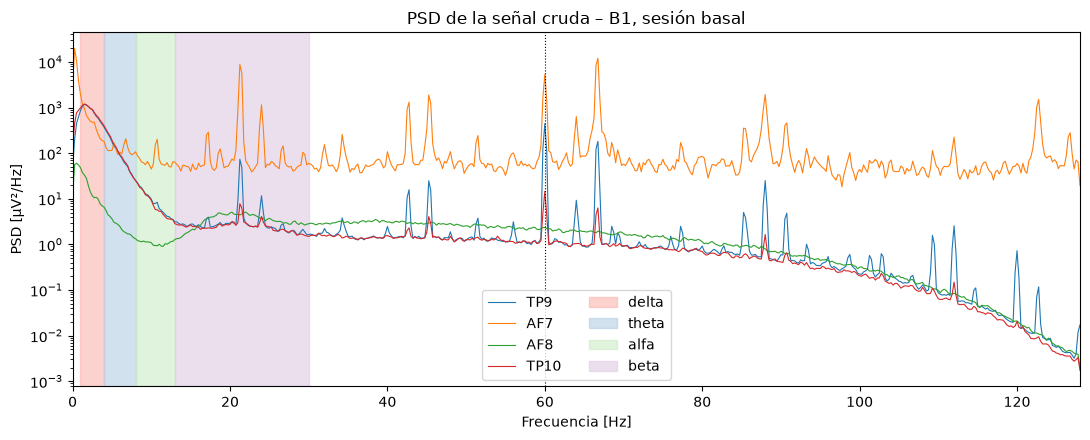

In [4]:
def psd(x, nperseg=4 * FS):
    return signal.welch(x - x.mean(axis=0), fs=FS, window='hann', nperseg=nperseg, axis=0)

f, p_crudo = psd(x)

fig, ax = plt.subplots(figsize=(11, 4.5))
for j, c in enumerate(CANALES):
    ax.semilogy(f, p_crudo[:, j], lw=0.8, label=c)
for (nombre, (fa, fb)), col in zip(BANDAS.items(), plt.cm.Pastel1.colors):
    ax.axvspan(fa, fb, color=col, alpha=0.6, label=nombre)
ax.axvline(F_LINEA, color='k', ls=':', lw=0.8)
ax.set_xlim(0, FS / 2)
ax.set_xlabel('Frecuencia [Hz]')
ax.set_ylabel('PSD [µV²/Hz]')
ax.set_title(f'PSD de la señal cruda – {s.sujeto}, sesión {r.condicion}')
ax.legend(ncol=2)
plt.tight_layout()

In [5]:
print("Cuánto sobresale el pico respecto de las bandas vecinas (≈ 1 si no hay pico):")
pd.DataFrame({f'{f0} Hz': [filtrado.potencia_relativa_en(x[:, j], FS, f0) for j in range(len(CANALES))]
              for f0 in (F_LINEA, 2 * F_LINEA)}, index=CANALES).round(2)

Cuánto sobresale el pico respecto de las bandas vecinas (≈ 1 si no hay pico):


,60 Hz,120 Hz
TP9,49.81,5.10
AF7,10.16,0.62
AF8,1.03,0.73
TP10,3.33,0.82


Se observa:
- **Pico en 60 Hz** (interferencia de la red eléctrica; el estudio se hizo en EE.UU.), de distinta magnitud según el canal.
- **Mucha potencia por debajo de 1 Hz** (deriva lenta de la línea de base).
- **AF7** tiene una PSD unas 100 veces mayor que los otros canales en casi todo el rango.
- **Otros picos angostos** además de 60 Hz, en TP9 y sobre todo en AF7, algunos dentro de la banda beta. Se identifican abajo.

El pico de 60 Hz y la deriva lenta justifican las dos etapas de esta parte: un filtro que cancele la interferencia de línea y un pasa banda que saque la deriva lenta y lo que hay por encima de beta.

### 1.1 Picos angostos dentro de 1–35 Hz

Se buscan frecuencias donde la PSD (Welch con ventanas de 16 s, resolución 1/16 Hz) supera 5 veces a la mediana de su entorno de ±1 Hz. Un ritmo cerebral es una banda ancha (varios Hz), no un pico de una fracción de Hz.

In [6]:
def picos_angostos(xc, umbral=5, rango=(1, 35)):
    f16, p16 = signal.welch(xc - xc.mean(), FS, nperseg=16 * FS)
    fondo = np.array([np.median(p16[max(0, i - 16):i + 16]) for i in range(len(p16))])
    idx, _ = signal.find_peaks(p16 / fondo, height=umbral, distance=8)
    idx = idx[(f16[idx] > rango[0]) & (f16[idx] <= rango[1])]
    return {round(float(f16[i]), 2): int(round(p16[i] / fondo[i])) for i in idx}

for j, c in enumerate(CANALES):
    print(f"{c:5s}", picos_angostos(x[:, j]) or '-', "   (frecuencia [Hz]: veces sobre el fondo)")

TP9   {21.31: 97, 24.0: 15, 34.31: 6}    (frecuencia [Hz]: veces sobre el fondo)
AF7   {10.69: 7, 17.12: 23, 18.69: 6, 21.31: 407, 24.0: 79, 26.62: 7, 34.31: 13}    (frecuencia [Hz]: veces sobre el fondo)
AF8   -    (frecuencia [Hz]: veces sobre el fondo)
TP10  {21.31: 8}    (frecuencia [Hz]: veces sobre el fondo)


Hay picos angostos en **21,31 Hz** y **24,00 Hz** (y otros más chicos en 17, 26,6 y 34,3 Hz), muy por encima del fondo, en los mismos canales donde la interferencia de 60 Hz es más fuerte. Están dentro de la banda beta: si no se tienen en cuenta, aumentan la potencia beta de esos canales. Su presencia en todos los sujetos se cuantifica en la sección 5; el pasa banda no los atenúa (están en la banda de paso) y el LMS solo cancela 60 Hz.

## 2. Filtro adaptativo LMS para la interferencia de 60 Hz

Configuración de **cancelación adaptativa de ruido (ANC)** con referencia sintética:

- **Entrada primaria:** el canal crudo, $x[n] = s[n] + i[n]$ (EEG + interferencia).
- **Referencia:** dos senoidales en cuadratura a la frecuencia de línea, $r_1[n] = \cos(2\pi\,60\,n/f_s)$ y $r_2[n] = \sin(2\pi\,60\,n/f_s)$. Con dos pesos se puede representar una senoidal de 60 Hz de cualquier amplitud y fase.
- **Salida del filtro:** $y[n] = w_1 r_1[n] + w_2 r_2[n]$, estimación de la interferencia.
- **Error = señal limpia:** $e[n] = x[n] - y[n]$.
- **Actualización** (descenso por gradiente estocástico del error cuadrático): $\mathbf{w} \leftarrow \mathbf{w} + 2\mu\, e[n]\, \mathbf{r}[n]$.

Como la referencia está correlacionada solo con la interferencia (no con el EEG), minimizar la potencia del error equivale a minimizar la potencia de la interferencia que queda.

**El paso μ:** la matriz de autocorrelación de la referencia es $R = E[\mathbf{r}\mathbf{r}^T] = \tfrac{1}{2} I$, con autovalor $\lambda = 1/2$. Entonces:
- el algoritmo converge en media si $0 < \mu < 1/\lambda_{max} = 2$;
- la constante de tiempo de los pesos es $\tau \approx 1/(2\mu\lambda) = 1/\mu$ muestras.

μ chico: converge lento y el *notch* que forma es angosto. μ grande: sigue rápido los cambios de la interferencia, pero el notch se ensancha y se come EEG de las frecuencias vecinas.

### 2.1 Verificación con una señal sintética

Antes de usarlo con el EEG se prueba con una señal de la que se conoce la respuesta: una senoidal de 10 Hz más ruido blanco (el "EEG") y una interferencia de 60 Hz de amplitud $A = 80$ µV y fase $\varphi = 0{,}7$ rad. Los pesos deben converger a $w_1 = A\cos\varphi$ y $w_2 = -A\sin\varphi$, y la componente de 10 Hz no debe cambiar.

Pesos finales:   [ 61.22 -51.49]
Pesos esperados: [ 61.19 -51.54]
PSD en 10 Hz después / antes: 1.002


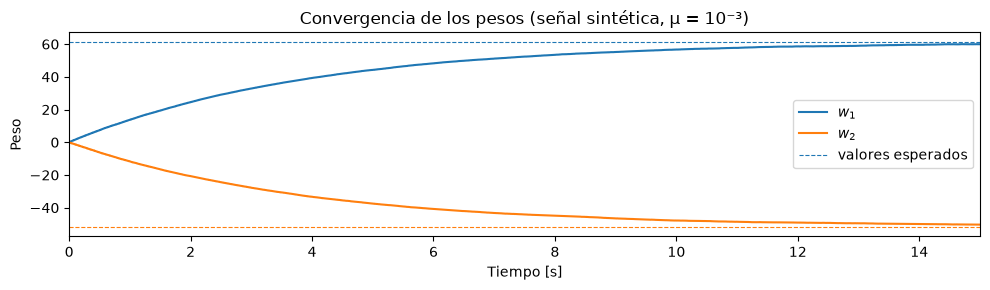

In [7]:
rng = np.random.default_rng(cfg['SEED'])
n = np.arange(60 * FS)
A, fi = 80.0, 0.7
eeg_sint = 20 * np.sin(2 * np.pi * 10 * n / FS) + 5 * rng.standard_normal(len(n))
x_sint = eeg_sint + A * np.cos(2 * np.pi * F_LINEA * n / FS + fi)

e_sint, w_sint = filtrado.lms_linea(x_sint, FS, F_LINEA, mu=1e-3)
print(f"Pesos finales:   {w_sint[-1].round(2)}")
print(f"Pesos esperados: {np.round([A * np.cos(fi), -A * np.sin(fi)], 2)}")

conv = slice(20 * FS, None)   # después de converger
f_s, p0 = signal.welch(eeg_sint[conv], FS, nperseg=4 * FS)
_, p1 = signal.welch(e_sint[conv], FS, nperseg=4 * FS)
print(f"PSD en 10 Hz después / antes: {p1[f_s == 10][0] / p0[f_s == 10][0]:.3f}")

fig, ax = plt.subplots(figsize=(10, 3))
ax.plot(n / FS, w_sint)
ax.axhline(A * np.cos(fi), color='C0', ls='--', lw=0.8)
ax.axhline(-A * np.sin(fi), color='C1', ls='--', lw=0.8)
ax.set_xlim(0, 15)
ax.set_xlabel('Tiempo [s]')
ax.set_ylabel('Peso')
ax.legend(['$w_1$', '$w_2$', 'valores esperados'])
ax.set_title('Convergencia de los pesos (señal sintética, μ = 10⁻³)')
plt.tight_layout()

### 2.2 Elección de μ sobre el EEG

Para cada μ candidato se aplica el LMS a cada canal de la sesión y se miden:
- **pico en 60 Hz** que queda (`potencia_relativa_en`): cociente entre la PSD en 59–61 Hz y la de las bandas vecinas; ≈ 1 significa que la interferencia quedó al nivel del fondo;
- **cuánto EEG vecino se pierde**: cociente entre la PSD después y antes del LMS a ±0,5, ±1 y ±2 Hz de 60 Hz (PSD de Welch con ventanas de 16 s para tener resolución de 1/16 Hz). Es el módulo al cuadrado de la respuesta en frecuencia del LMS visto como filtro: 1 = no se pierde nada.

Se descartan los primeros 30 s (convergencia inicial).

In [8]:
MUS = [3e-4, 1e-3, 2e-3, 3e-3, 5e-3, 1e-2]
DESCARTE = 30 * FS

filas = []
salidas = {}
for j, c in enumerate(CANALES):
    xc = x[:, j] - x[:, j].mean()
    f16, pa = signal.welch(xc[DESCARTE:], FS, nperseg=16 * FS)
    for mu in MUS:
        e, w = filtrado.lms_linea(xc, FS, F_LINEA, mu)
        salidas[c, mu] = (e, w)
        _, pd_ = signal.welch(e[DESCARTE:], FS, nperseg=16 * FS)
        H2 = lambda d: np.mean([(pd_ / pa)[np.argmin(abs(f16 - (F_LINEA + sg * d)))] for sg in (-1, 1)])
        filas.append({'canal': c, 'mu': mu,
                      'pico60_antes': filtrado.potencia_relativa_en(xc[DESCARTE:], FS, F_LINEA),
                      'pico60_despues': filtrado.potencia_relativa_en(e[DESCARTE:], FS, F_LINEA),
                      'H2_0.5Hz': H2(0.5), 'H2_1Hz': H2(1), 'H2_2Hz': H2(2)})
barrido = pd.DataFrame(filas)
barrido.round({'pico60_antes': 2, 'pico60_despues': 2, 'H2_0.5Hz': 2, 'H2_1Hz': 2, 'H2_2Hz': 2})

,canal,mu,pico60_antes,pico60_despues,H2_0.5Hz,H2_1Hz,H2_2Hz
0,TP9,0.0003,51.59,22.27,1.00,1.00,1.00
1,TP9,0.0010,51.59,6.49,0.99,1.00,1.00
2,TP9,0.0020,51.59,2.43,0.98,1.00,1.00
3,TP9,0.0030,51.59,1.42,0.95,0.99,1.00
4,TP9,0.0050,51.59,0.80,0.86,0.97,1.00
5,TP9,0.0100,51.59,0.42,0.61,0.87,0.98
6,AF7,0.0003,10.95,5.74,1.00,1.00,1.00
7,AF7,0.0010,10.95,2.51,1.00,1.00,1.00
8,AF7,0.0020,10.95,1.50,0.98,1.00,1.00
9,AF7,0.0030,10.95,1.15,0.96,0.99,1.00


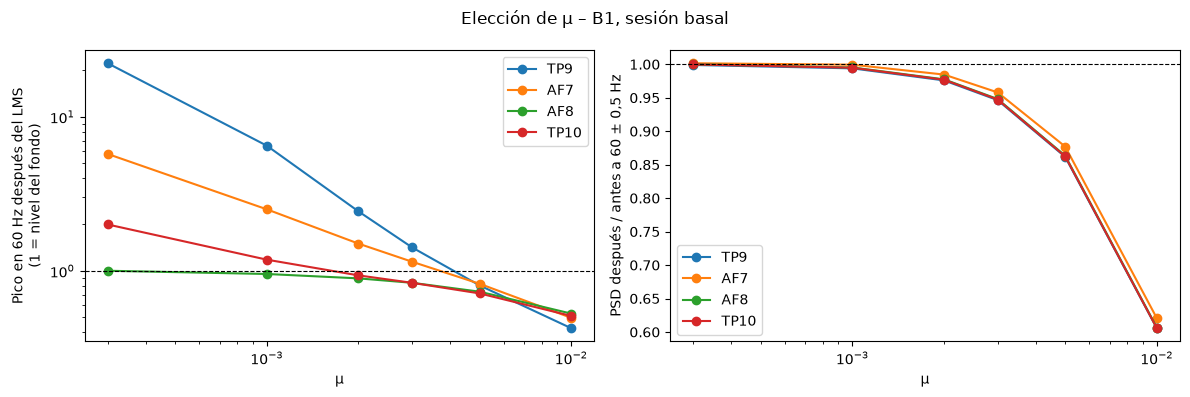

In [9]:
fig, axs = plt.subplots(1, 2, figsize=(12, 4))
for c in CANALES:
    b = barrido[barrido.canal == c]
    axs[0].semilogx(b.mu, b.pico60_despues, 'o-', label=c)
    axs[1].semilogx(b.mu, b['H2_0.5Hz'], 'o-', label=c)
axs[0].axhline(1, color='k', ls='--', lw=0.8)
axs[0].set_ylabel('Pico en 60 Hz después del LMS\n(1 = nivel del fondo)')
axs[0].set_yscale('log')
axs[1].axhline(1, color='k', ls='--', lw=0.8)
axs[1].set_ylabel('PSD después / antes a 60 ± 0,5 Hz')
for ax in axs:
    ax.set_xlabel('μ')
    ax.legend()
fig.suptitle(f'Elección de μ – {s.sujeto}, sesión {r.condicion}')
plt.tight_layout()

Hay un compromiso: con μ chico (≤ 10⁻³) queda interferencia en los canales donde es más fuerte (TP9, AF7); con μ grande (≥ 5·10⁻³) el pico queda por debajo del fondo, es decir, el filtro ya está sacando EEG alrededor de 60 Hz, y a ±0,5 Hz se pierde más del 10 % de la potencia.

En la señal sintética μ = 10⁻³ alcanzaba. En el EEG real no, porque la amplitud y la fase de la interferencia varían a lo largo de la sesión (ver los pesos en la figura siguiente) y el filtro tiene que seguirlas: la constante de tiempo $\tau = 1/\mu$ tiene que ser más corta que esas variaciones.

μ = 0.003  ->  τ = 1/μ = 333 muestras = 1.30 s


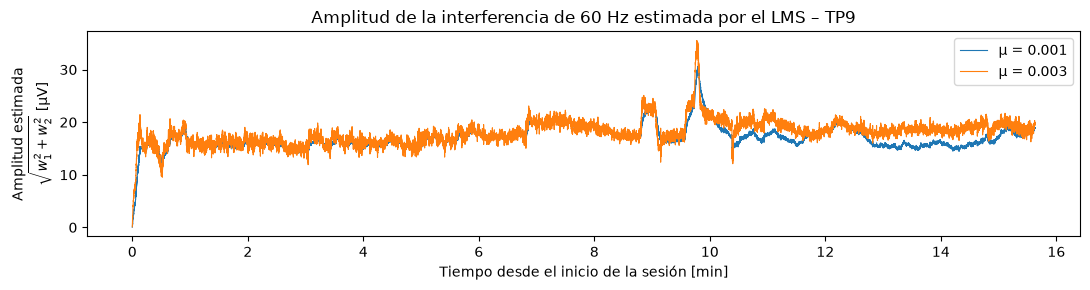

In [10]:
MU = 3e-3   # elegido en el barrido (se confirma en todos los sujetos en la sección 5)
print(f"μ = {MU:g}  ->  τ = 1/μ = {1 / MU:.0f} muestras = {1 / MU / FS:.2f} s")

c = 'TP9'
fig, ax = plt.subplots(figsize=(11, 3))
tt = np.arange(len(x)) / FS / 60
for mu in (1e-3, MU):
    w = salidas[c, mu][1]
    ax.plot(tt, np.hypot(w[:, 0], w[:, 1]), lw=0.8, label=f'μ = {mu:g}')
ax.set_xlabel('Tiempo desde el inicio de la sesión [min]')
ax.set_ylabel('Amplitud estimada\n$\\sqrt{w_1^2 + w_2^2}$ [µV]')
ax.set_title(f'Amplitud de la interferencia de 60 Hz estimada por el LMS – {c}')
ax.legend()
plt.tight_layout()

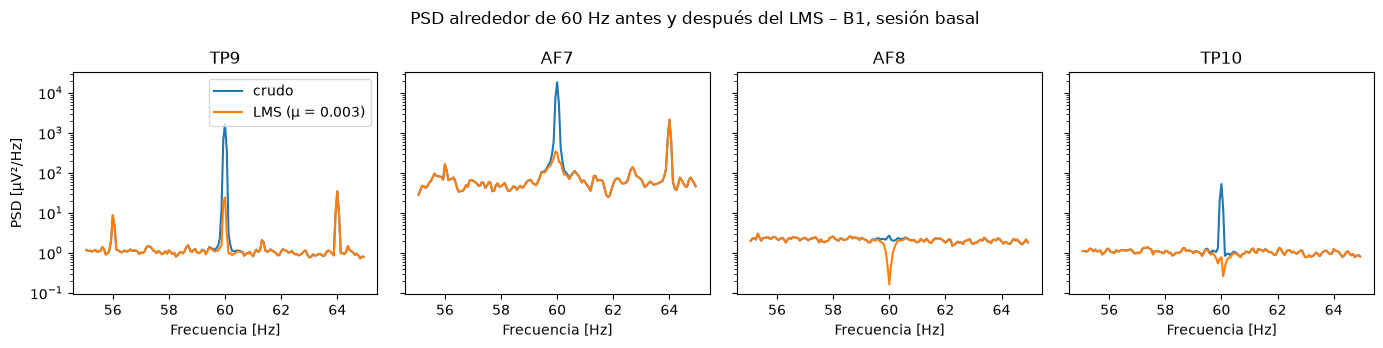

In [11]:
fig, axs = plt.subplots(1, len(CANALES), figsize=(14, 3.5), sharey=True)
for ax, (j, c) in zip(axs, enumerate(CANALES)):
    xc = x[:, j] - x[:, j].mean()
    f16, pa = signal.welch(xc[DESCARTE:], FS, nperseg=16 * FS)
    _, pdes = signal.welch(salidas[c, MU][0][DESCARTE:], FS, nperseg=16 * FS)
    m = (f16 > 55) & (f16 < 65)
    ax.semilogy(f16[m], pa[m], label='crudo')
    ax.semilogy(f16[m], pdes[m], label=f'LMS (μ = {MU:g})')
    ax.set_title(c)
    ax.set_xlabel('Frecuencia [Hz]')
axs[0].set_ylabel('PSD [µV²/Hz]')
axs[0].legend()
fig.suptitle(f'PSD alrededor de 60 Hz antes y después del LMS – {s.sujeto}, sesión {r.condicion}')
plt.tight_layout()

## 3. Pasa banda Butterworth

- **Tipo:** Butterworth, respuesta máximamente plana en la banda de paso (no distorsiona la amplitud relativa entre bandas).
- **Fase cero:** se aplica con `filtfilt` (ida y vuelta), así no hay retardo que corra la señal respecto de los bloques. La atenuación en dB se duplica y el orden efectivo también.
- **Forma SOS** (secciones de segundo orden), por estabilidad numérica.
- **Corte inferior 1 Hz:** saca la deriva lenta que se ve en la PSD cruda. Por eso la banda delta se toma desde 1 Hz.
- **Corte superior 40 Hz:** deja margen sobre beta (30 Hz) y atenúa lo que queda de la interferencia y el armónico de 120 Hz.

Para elegir el orden se compara la atenuación (con `filtfilt`) en las frecuencias clave:

In [12]:
f_clave = [0.5, 1, 4, 13, 30, 40, 60, 120]
tabla_orden = {}
for orden in (2, 4, 6):
    sos_o = filtrado.disenar_pasabanda(FS, orden=orden)
    _, h = signal.sosfreqz(sos_o, worN=f_clave, fs=FS)
    tabla_orden[orden] = 2 * 20 * np.log10(np.abs(h))   # ×2 por filtfilt
pd.DataFrame(tabla_orden, index=[f'{f} Hz' for f in f_clave]).T.rename_axis('orden').round(1)

,0.5 Hz,1 Hz,4 Hz,13 Hz,30 Hz,40 Hz,60 Hz,120 Hz
orden,,,,,,,,
2,-25.2,-6.0,-0.0,-0.0,-1.9,-6.0,-19.8,-103.1
4,-49.4,-6.0,-0.0,-0.0,-0.5,-6.0,-37.9,-206.2
6,-74.1,-6.0,-0.0,-0.0,-0.1,-6.0,-56.6,-309.3


Con orden 2 la banda beta pierde casi 2 dB en 30 Hz. Con **orden 4** la banda de 2 a 30 Hz queda plana (pérdida < 0,5 dB) y en 60 Hz atenúa unos 38 dB; un orden mayor no mejora la banda de interés, que ya es plana. Se elige **orden 4**.

En las frecuencias de corte (1 y 40 Hz) la atenuación es de 6 dB (−3 dB por pasada): el borde inferior de delta queda atenuado a la mitad de potencia.

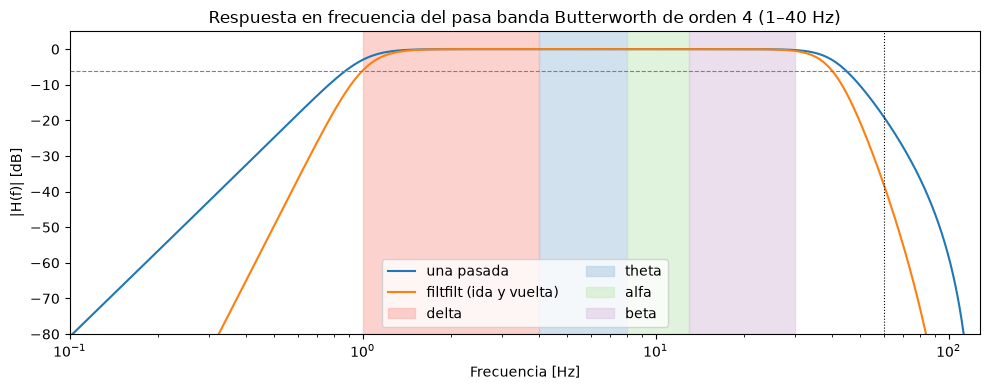

In [13]:
sos = filtrado.disenar_pasabanda(FS, f_bajo=1.0, f_alto=40.0, orden=4)
f_h, h_db = filtrado.respuesta_frecuencia(sos, FS)

fig, ax = plt.subplots(figsize=(10, 4))
ax.semilogx(f_h[1:], h_db[1:], label='una pasada')
ax.semilogx(f_h[1:], 2 * h_db[1:], label='filtfilt (ida y vuelta)')
for (nombre, (fa, fb)), col in zip(BANDAS.items(), plt.cm.Pastel1.colors):
    ax.axvspan(fa, fb, color=col, alpha=0.6, label=nombre)
ax.axvline(F_LINEA, color='k', ls=':', lw=0.8)
ax.axhline(-6, color='gray', ls='--', lw=0.8)
ax.set_ylim(-80, 5)
ax.set_xlim(0.1, FS / 2)
ax.set_xlabel('Frecuencia [Hz]')
ax.set_ylabel('|H(f)| [dB]')
ax.set_title('Respuesta en frecuencia del pasa banda Butterworth de orden 4 (1–40 Hz)')
ax.legend(ncol=2, loc='lower center')
plt.tight_layout()

## 4. Cadena completa: LMS + pasa banda

Se aplica la cadena (`filtrado.filtrar`) a la sesión y se compara la PSD y la señal en el tiempo antes y después.

Los transitorios del comienzo (convergencia del LMS, $\tau$ < 1 s) y de los bordes del `filtfilt` caen en el margen de 12–22 s que hay entre cada tag y el primer estímulo (Parte 0), así que no afectan a los bloques de la tarea.

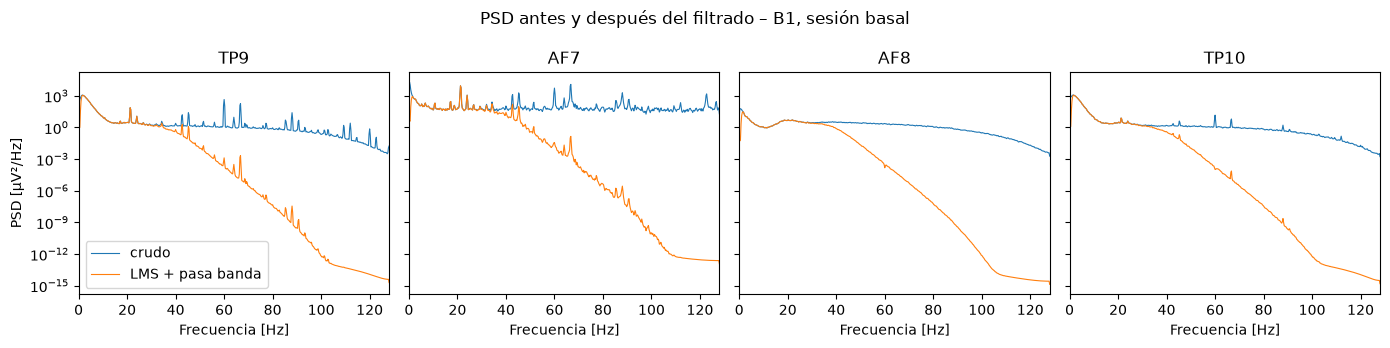

In [14]:
x_filt = filtrado.filtrar(x, FS, sos, F_LINEA, MU)
f, p_filt = psd(x_filt)

fig, axs = plt.subplots(1, len(CANALES), figsize=(14, 3.5), sharey=True)
for ax, (j, c) in zip(axs, enumerate(CANALES)):
    ax.semilogy(f, p_crudo[:, j], lw=0.8, label='crudo')
    ax.semilogy(f, p_filt[:, j], lw=0.8, label='LMS + pasa banda')
    ax.set_xlim(0, FS / 2)
    ax.set_title(c)
    ax.set_xlabel('Frecuencia [Hz]')
axs[0].set_ylabel('PSD [µV²/Hz]')
axs[0].legend()
fig.suptitle(f'PSD antes y después del filtrado – {s.sujeto}, sesión {r.condicion}')
plt.tight_layout()

In [15]:
i60 = np.argmin(abs(f - F_LINEA))
_, p_bp = psd(filtrado.aplicar_pasabanda(x - x.mean(axis=0), sos))
pd.DataFrame({
    'crudo': p_crudo[i60],
    'solo pasa banda': p_bp[i60],
    'LMS + pasa banda': p_filt[i60],
}, index=CANALES).rename_axis('PSD en 60 Hz [µV²/Hz]').round(4)

,crudo,solo pasa banda,LMS + pasa banda
PSD en 60 Hz [µV²/Hz],,,
TP9,444.1397,0.0729,0.0013
AF7,5358.0203,0.8782,0.0376
AF8,2.3501,0.0004,0.0002
TP10,14.5989,0.0024,0.0001


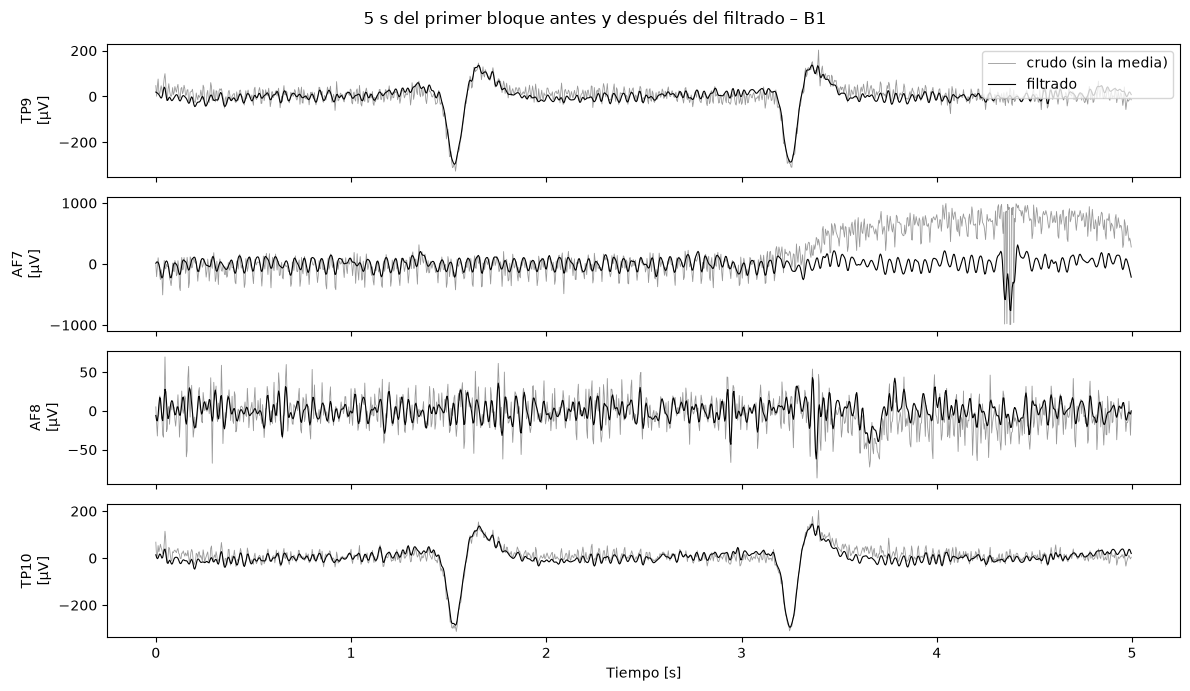

In [16]:
b0 = datos.tabla_bloques(datos.cargar_nback(s.ruta)).iloc[0]
i0 = int((b0.t_ini - r.tag_ini) * FS)
seg = slice(i0, i0 + 5 * FS)
tt = np.arange(5 * FS) / FS

fig, axs = plt.subplots(len(CANALES), 1, sharex=True, figsize=(12, 7))
for ax, (j, c) in zip(axs, enumerate(CANALES)):
    ax.plot(tt, x[seg, j] - x[:, j].mean(), lw=0.6, color='0.6', label='crudo (sin la media)')
    ax.plot(tt, x_filt[seg, j], lw=0.8, color='k', label='filtrado')
    ax.set_ylabel(f'{c}\n[µV]')
axs[0].legend(loc='upper right')
axs[-1].set_xlabel('Tiempo [s]')
fig.suptitle(f'5 s del primer bloque antes y después del filtrado – {s.sujeto}')
plt.tight_layout()

## 5. Verificación en todos los sujetos

Para cada sujeto, sesión y canal se aplica el LMS con el μ elegido y se mide el pico en 60 Hz antes y después, y la pérdida de EEG a ±0,5 Hz de 60 Hz.

In [17]:
filas = []
for suj in sujetos.itertuples():
    t_s, eeg_s = datos.cargar_eeg(suj.ruta)
    for r_s in datos.tabla_sesiones(suj.ruta).itertuples():
        _, xs = datos.recortar(t_s, eeg_s, r_s.tag_ini, r_s.tag_fin)
        for c in CANALES:
            xc = xs[c].to_numpy() - xs[c].mean()
            e, _ = filtrado.lms_linea(xc, FS, F_LINEA, MU)
            f16, pa = signal.welch(xc[DESCARTE:], FS, nperseg=16 * FS)
            _, pdes = signal.welch(e[DESCARTE:], FS, nperseg=16 * FS)
            h2 = np.mean([(pdes / pa)[np.argmin(abs(f16 - (F_LINEA + sg * 0.5)))] for sg in (-1, 1)])
            filas.append({'sujeto': suj.sujeto, 'condicion': r_s.condicion, 'canal': c,
                          'pico60_antes': filtrado.potencia_relativa_en(xc[DESCARTE:], FS, F_LINEA),
                          'pico60_despues': filtrado.potencia_relativa_en(e[DESCARTE:], FS, F_LINEA),
                          'H2_0.5Hz': h2,
                          'pico_21.3Hz': picos_angostos(xc).get(21.31, np.nan),
                          'pico_24Hz': picos_angostos(xc).get(24.0, np.nan)})
lms_todos = pd.DataFrame(filas)
lms_todos.groupby('canal')[['pico60_antes', 'pico60_despues', 'H2_0.5Hz']].describe().T.round(2)

canal                   AF7    AF8   TP10    TP9
pico60_antes   count  70.00  70.00  70.00  70.00
               mean    5.97   5.80   7.69   3.45
               std    16.34  19.52  18.35   8.59
               min     0.43   0.50   0.67   0.88
               25%     0.96   0.95   1.04   1.02
               50%     1.02   1.01   1.28   1.15
               75%     1.21   1.15   1.95   1.35
               max    96.41  93.93  89.89  51.59
pico60_despues count  70.00  70.00  70.00  70.00
               mean    1.07   0.93   1.91   0.91
               std     0.86   0.39   3.25   0.26
               min     0.35   0.43   0.58   0.67
               25%     0.78   0.78   0.78   0.80
               50%     0.83   0.83   0.85   0.83
               75%     0.91   0.93   0.92   0.91
               max     5.09   2.88  16.26   2.13
H2_0.5Hz       count  70.00  70.00  70.00  70.00
               mean    0.95   0.95   0.95   0.95
               std     0.00   0.00   0.00   0.00
               min     0.94   0.93   0.94   0.94
               25%     0.95   0.95   0.95   0.95
               50%     0.95   0.95   0.95   0.95
               75%     0.95   0.95   0.95   0.95
               max     0.96   0.96   0.96   0.96

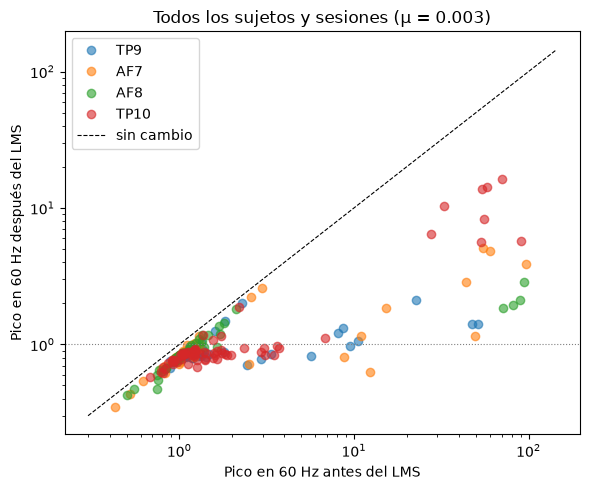

In [18]:
fig, ax = plt.subplots(figsize=(6, 5))
for c in CANALES:
    d = lms_todos[lms_todos.canal == c]
    ax.loglog(d.pico60_antes, d.pico60_despues, 'o', alpha=0.6, label=c)
lim = [0.3, lms_todos.pico60_antes.max() * 1.5]
ax.plot(lim, lim, 'k--', lw=0.8, label='sin cambio')
ax.axhline(1, color='gray', ls=':', lw=0.8)
ax.set_xlabel('Pico en 60 Hz antes del LMS')
ax.set_ylabel('Pico en 60 Hz después del LMS')
ax.set_title(f'Todos los sujetos y sesiones (μ = {MU:g})')
ax.legend()
plt.tight_layout()

In [19]:
print("Sesiones-canal con pico en 60 Hz > 2 después del LMS:")
lms_todos[lms_todos.pico60_despues > 2].round(2)

Sesiones-canal con pico en 60 Hz > 2 después del LMS:


,sujeto,condicion,canal,pico60_antes,pico60_despues,H2_0.5Hz,pico_21.3Hz,pico_24Hz
35,A3,sin_musica,TP10,57.86,14.27,0.95,NaN,NaN
39,A3,relajante,TP10,54.18,13.74,0.95,NaN,NaN
43,A3,estimulante,TP10,70.87,16.26,0.95,NaN,NaN
47,A3,ia,TP10,32.87,10.26,0.95,NaN,NaN
49,A4,sin_musica,AF7,59.84,4.82,0.95,479.0,72.0
53,A4,relajante,AF7,96.41,3.89,0.95,695.0,87.0
57,A4,estimulante,AF7,43.92,2.85,0.95,507.0,64.0
61,A4,ia,AF7,55.09,5.09,0.95,539.0,72.0
89,A6,estimulante,AF7,2.56,2.23,0.96,NaN,NaN
131,A9,sin_musica,TP10,89.89,5.74,0.95,NaN,NaN


Picos angostos en 21,31 Hz y 24 Hz (veces sobre el fondo; vacío = no supera 5 veces el fondo), por sujeto y canal (máximo entre sesiones):

In [20]:
lms_todos.groupby(['sujeto', 'canal'], sort=False)[['pico_21.3Hz', 'pico_24Hz']].max().unstack('canal')

pico_21.3Hz                     pico_24Hz                   
canal          TP9     AF7    AF8 TP10       TP9    AF7    AF8 TP10
sujeto                                                             
A1             NaN     NaN    NaN  NaN       NaN    NaN    NaN  NaN
A2             NaN     NaN    NaN  NaN       NaN    NaN    NaN  NaN
A3             NaN     NaN    NaN  NaN       NaN    NaN    NaN  NaN
A4             NaN   695.0    NaN  5.0       NaN   87.0    NaN  NaN
A5             NaN     NaN    NaN  NaN       NaN    NaN    NaN  NaN
A6             NaN     NaN    NaN  NaN       NaN    NaN    NaN  NaN
A7             NaN     NaN    NaN  NaN       NaN    NaN    NaN  NaN
A8             NaN     NaN    NaN  NaN       NaN    NaN    NaN  NaN
A9             NaN     NaN  716.0  NaN       NaN    NaN  113.0  NaN
A10            NaN     NaN    NaN  8.0       NaN    NaN    NaN  NaN
B1           155.0  1075.0    NaN  8.0      18.0  115.0    NaN  NaN
B2             NaN     NaN    NaN  NaN       NaN    NaN    NaN  NaN
B3             NaN     NaN    7.0  NaN       NaN    NaN    NaN  NaN
B4             NaN     NaN    NaN  8.0       NaN    NaN    NaN  NaN
B5             NaN   779.0    NaN  NaN       NaN  104.0    NaN  NaN
B6             NaN     NaN    NaN  NaN       NaN    NaN    NaN  NaN
B7             NaN     NaN    NaN  NaN       NaN    NaN    NaN  NaN
B8             NaN     NaN    NaN  NaN       NaN    NaN    NaN  NaN
B9             NaN     NaN    NaN  7.0       NaN    NaN    NaN  NaN
B10            NaN     NaN    NaN  NaN       NaN    NaN    NaN  NaN

### 5.1 Casos en que el LMS deja un residuo

En unos pocos canales con interferencia muy fuerte el pico de 60 Hz no queda al nivel del fondo después del LMS. El caso más marcado es **A3 – TP10**. Se mide la amplitud de la componente de 60 Hz en ventanas de 1 s (proyección de la señal sobre $e^{-j2\pi 60 n/f_s}$):

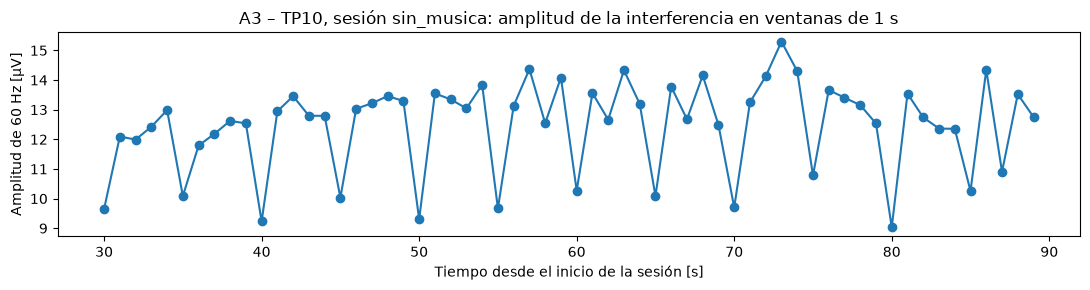

In [21]:
s3 = sujetos.query("sujeto == 'A3'").iloc[0]
t3, eeg3 = datos.cargar_eeg(s3.ruta)
r3 = datos.tabla_sesiones(s3.ruta).iloc[0]
_, x3 = datos.recortar(t3, eeg3, r3.tag_ini, r3.tag_fin)
x3 = x3['TP10'].to_numpy() - x3['TP10'].mean()

n3 = np.arange(len(x3))
z = x3 * np.exp(-2j * np.pi * F_LINEA * n3 / FS)
amp_1s = 2 * np.abs(np.convolve(z, np.ones(FS) / FS, 'valid'))[::FS]

fig, ax = plt.subplots(figsize=(11, 3))
ax.plot(np.arange(len(amp_1s))[30:90], amp_1s[30:90], 'o-')
ax.set_xlabel('Tiempo desde el inicio de la sesión [s]')
ax.set_ylabel('Amplitud de 60 Hz [µV]')
ax.set_title(f'A3 – TP10, sesión {r3.condicion}: amplitud de la interferencia en ventanas de 1 s')
plt.tight_layout()

La amplitud de la interferencia cae cada 5 s. Esa modulación produce bandas laterales en 60 ± 0,2 Hz que el LMS, con $	au$ = 1,3 s, no llega a seguir. Aumentar μ lo resolvería en este canal, pero ensancharía el notch en todos los demás (sección 2.2).

Lo que importa es si el residuo afecta las bandas de análisis. Para cada caso con pico > 2 después del LMS se aplica la cadena completa y se compara la potencia que queda en 59–61 Hz con la potencia en beta (13–30 Hz):

In [22]:
from scipy import integrate

def pot_banda(f, p, a, b):
    m = (f >= a) & (f < b)
    return integrate.trapezoid(p[m], f[m])

filas = []
for caso in lms_todos[lms_todos.pico60_despues > 2].itertuples():
    sj = sujetos.query("sujeto == @caso.sujeto").iloc[0]
    tj, eegj = datos.cargar_eeg(sj.ruta)
    rj = datos.tabla_sesiones(sj.ruta).query("condicion == @caso.condicion").iloc[0]
    _, xj = datos.recortar(tj, eegj, rj.tag_ini, rj.tag_fin)
    y = filtrado.filtrar(xj[[caso.canal]].to_numpy(), FS, sos, F_LINEA, MU)[DESCARTE:, 0]
    fj, pj = signal.welch(y, FS, nperseg=4 * FS)
    filas.append({'sujeto': caso.sujeto, 'condicion': caso.condicion, 'canal': caso.canal,
                  'pot_59_61Hz': pot_banda(fj, pj, 59, 61), 'pot_beta': pot_banda(fj, pj, 13, 30)})
residuo = pd.DataFrame(filas)
residuo['cociente'] = residuo.pot_59_61Hz / residuo.pot_beta
print(f"Cociente máximo (potencia 59-61 Hz / potencia beta): {residuo.cociente.max():.1e}")
residuo.round(4)

Cociente máximo (potencia 59-61 Hz / potencia beta): 5.5e-04


,sujeto,condicion,canal,pot_59_61Hz,pot_beta,cociente
0,A3,sin_musica,TP10,0.0032,23.4331,0.0001
1,A3,relajante,TP10,0.0036,26.0480,0.0001
2,A3,estimulante,TP10,0.0062,31.6671,0.0002
3,A3,ia,TP10,0.0069,30.6820,0.0002
4,A4,sin_musica,AF7,0.1765,5642.3696,0.0000
5,A4,relajante,AF7,0.0871,5369.5139,0.0000
6,A4,estimulante,AF7,0.1258,5553.3190,0.0000
7,A4,ia,AF7,0.1825,5562.6285,0.0000
8,A6,estimulante,AF7,0.0003,17.3931,0.0000
9,A9,sin_musica,TP10,1.4134,3163.3669,0.0004


## 6. Conclusiones

1. **Espectro crudo:** muestra un pico de 60 Hz (interferencia de línea), mucha potencia por debajo de 1 Hz (deriva lenta) y, en algunos canales, picos angostos en otras frecuencias (punto 5). Esto justifica las dos etapas de filtrado.
2. **LMS (cancelación adaptativa de 60 Hz):**
   - Con una señal sintética los pesos convergen a la amplitud y fase exactas de la interferencia y la componente de 10 Hz no cambia.
   - El paso se eligió con un barrido sobre el EEG: **μ = 3·10⁻³** ($	au$ = 1/μ = 333 muestras = 1,3 s). Con μ ≤ 10⁻³ queda interferencia en los canales donde es fuerte; con μ ≥ 5·10⁻³ el notch se ensancha y se pierde más del 10 % de la potencia a ±0,5 Hz de 60 Hz. Con el μ elegido la pérdida a ±0,5 Hz es de entre el 4 y el 7 % en los 280 casos sesión-canal (en B1, a ±1 Hz es del 1 %).
   - En los 20 sujetos (280 casos sesión-canal) el pico en 60 Hz pasa de una mediana de 1,0–1,3 (máximo 96) a 0,8 (máximo 16). Los casos que quedan por encima de 2 son canales con interferencia muy fuerte; en el caso extremo (A3 – TP10) la amplitud de la interferencia está modulada cada 5 s y el LMS no la sigue. Después del pasa banda, la potencia que queda en 59–61 Hz es como máximo el 0,06 % de la potencia beta en todos esos casos: **no afecta las bandas de análisis**.
3. **Pasa banda:** Butterworth de **orden 4**, 1–40 Hz, forma SOS, aplicado con `filtfilt` (fase cero). Es el menor orden que deja la banda de 2 a 30 Hz plana (< 0,5 dB de pérdida con `filtfilt`); atenúa 38 dB en 60 Hz. En las frecuencias de corte la atenuación es de 6 dB, así que el borde inferior de delta (1 Hz) queda a la mitad de potencia.
4. **Transitorios:** la convergencia del LMS ($	au$ = 1,3 s) y los bordes del `filtfilt` caen en el margen entre el tag de inicio y el primer estímulo (6 a 90 s, Parte 0), fuera de los bloques de la tarea.
5. **Picos angostos dentro de la banda beta:** hay picos angostos en **21,31 Hz** y **24,00 Hz** (y otros menores en 17, 26,6 y 34,3 Hz) muy por encima del fondo (entre 70 y 1000 veces) en **A4 – AF7, A9 – AF8, B1 – AF7 y TP9, y B5 – AF7**: son los mismos canales que en la Parte 0 tenían el desvío estándar más alto. En algunos TP10 aparecen picos chicos en 21,31 Hz (5 a 8 veces el fondo). Ni el LMS (que solo cancela 60 Hz) ni el pasa banda (están en la banda de paso) los atenúan, así que **aumentan la potencia beta de esos canales**. Su origen no se determinó. Se tienen que tener en cuenta en la Parte 2 al decidir qué canales se usan.